# Al–OH band

> Measure the sharp Al–OH band near 3620 cm⁻¹, which the OSSL Kex model relies on most, in the Fukushima Thermo and Bruker spectra and their OSSL analogues, and test whether it still tracks Kex

In [ ]:
#| default_exp bands

In [ ]:
#| export
import numpy as np
from scipy.signal import savgol_filter

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspectfm.preprocessing import SNV
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.moisture import band_height

`17_importance` found that the OSSL Kex model relies most densely on 3600–3700 cm⁻¹, with the Al–OH stretching band of illite, smectite and kaolinite near 3620 cm⁻¹ the most important window. `16_moisture` found the Thermo spectra much higher than their OSSL analogues between 3450 and 3700 cm⁻¹. A broad absorption there could hide the sharp band. This notebook measures the band directly.

The module part uses small random arrays, so it runs without the data. The sections from *Data* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Band depth

`band_depth` measures how sharp a band is: minus the minimum of the Savitzky-Golay second derivative within `half` cm⁻¹ of `center`. A sharp band gives a deep negative second derivative, and a broad absorption underneath it adds almost nothing. A window of 11 points is 22 cm⁻¹ on the 2 cm⁻¹ grid. `sharp_bands` holds the two bands measured here, with the ranges and anchors that `band_height` uses for the second measure:

In [ ]:
#| export
sharp_bands = { # Name: (centre, band range, low anchor, high anchor), in cm⁻¹
    'Al–OH 3620': (3620, (3612, 3630), (3570, 3585), (3638, 3646)),
    'kaolinite 3695': (3695, (3688, 3702), (3672, 3680), (3720, 3735))}

def band_depth(
    X, # Spectra, one per row
    wns, # Wavenumbers of the columns of `X`, evenly spaced
    center, # Band centre, in cm⁻¹
    half=6, # Half-width of the search range, in cm⁻¹
    window=11, # Savitzky-Golay window, in points
)->np.ndarray: # One depth per spectrum, positive for a band
    "Minus the minimum of the second derivative of `X` within `half` of `center`"
    wns = np.asarray(wns)
    d2 = savgol_filter(np.asarray(X, dtype=float), window, 3, deriv=2, axis=-1)
    return -d2[:, np.abs(wns - center) <= half].min(1)

In [ ]:
wns_syn = np.arange(3400, 3800, 2.)
broad = np.exp(-0.5 * ((wns_syn - 3500) / 150)**2)
sharp = np.exp(-0.5 * ((wns_syn - 3620) / 8)**2)
d = band_depth(np.stack([broad, broad + 0.1 * sharp, 3 * broad + 0.1 * sharp]), wns_syn, 3620)
test_eq(d[0] < 0.02 * d[1], True)
test_close(d[1], d[2], eps=0.05 * d[1])

## Data

SNV spectra on 650–3996 cm⁻¹, the range the Bruker exports cover: the Fukushima Thermo spectra of the current selection, the Thermo and Bruker spectra of the paired soils, 10,000 random OSSL spectra, and each Fukushima soil's OSSL analogue, matched as in `12_wetchem`. Kex and clay come from `fuku_shared_props` and `ossl_shared_props`:

In [ ]:
#| fukudata
pw = shared_wns[:-1]
snv = SNV()
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
ossl = ossl_shared_props(om)
op = prop_features(ossl)
sc_p = StandardScaler().fit(op)
nn = NearestNeighbors(n_neighbors=1).fit(sc_p.transform(op))
opos = pd.Series(np.arange(len(om.sample_ids)), index=om.sample_ids)
def analogues(ids):
    fp = prop_features(fuku_shared_props(ids))
    return fp.index, op.index[nn.kneighbors(sc_p.transform(fp))[1][:, 0]]
f_ids, f_an = analogues(sample_ids())
p_ids = [i for i in sorted(bruker_files(), key=int) if i not in excluded and i in set(spa_files())]
p_ids, p_an = analogues(p_ids)
o_sub = np.random.default_rng(0).choice(len(om.sample_ids), 10000, replace=False)
spec = {'Fukushima Thermo': snv.fit_transform(load_fuku(pw, list(f_ids)).spectra),
        'analogues of Fukushima': snv.fit_transform(om.spectra[opos[f_an].to_numpy()][:, :-1]),
        'paired Thermo': snv.fit_transform(load_fuku(pw, list(p_ids)).spectra),
        'paired Bruker': snv.fit_transform(load_bruker(pw, list(p_ids)).spectra),
        'analogues of paired': snv.fit_transform(om.spectra[opos[p_an].to_numpy()][:, :-1]),
        'OSSL': snv.fit_transform(om.spectra[o_sub][:, :-1])}
fprops = fuku_shared_props(list(f_ids)); pprops = fuku_shared_props(list(p_ids))
props = {'Fukushima Thermo': fprops, 'analogues of Fukushima': ossl.loc[f_an], 'paired Thermo': pprops, 'paired Bruker': pprops,
         'analogues of paired': ossl.loc[p_an], 'OSSL': ossl.iloc[o_sub]}
{k: len(v) for k, v in spec.items()}

{'Fukushima Thermo': 1385,
 'analogues of Fukushima': 1385,
 'paired Thermo': 375,
 'paired Bruker': 375,
 'analogues of paired': 375,
 'OSSL': 10000}

The mean SNV spectrum of each set between 3500 and 3800 cm⁻¹, with the two bands marked:

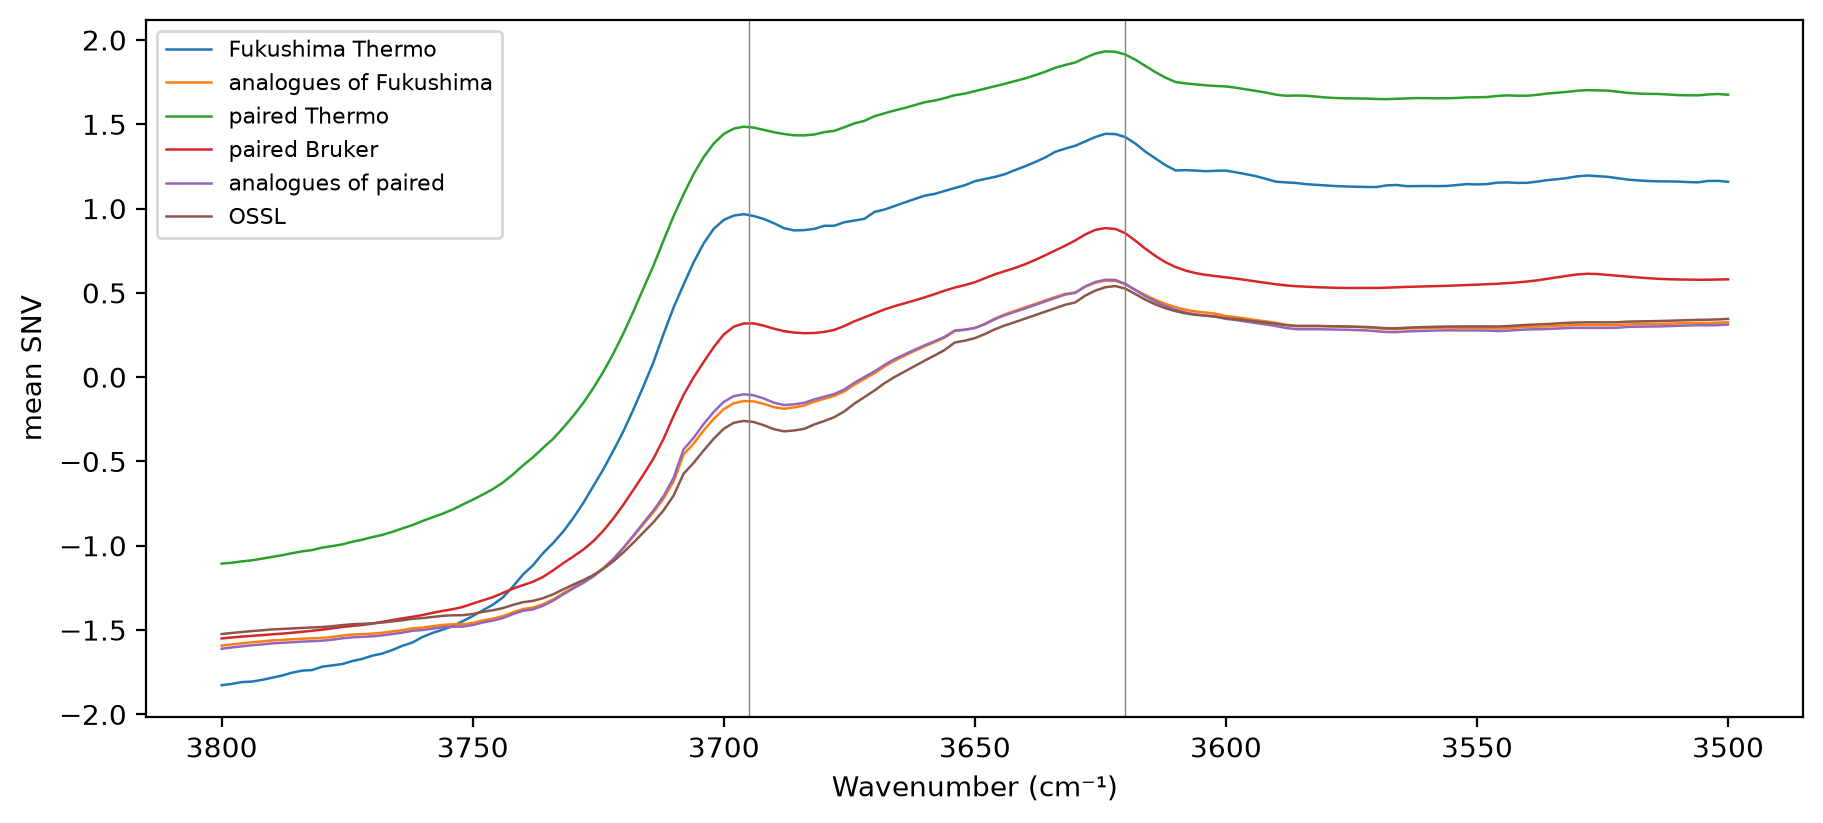

In [ ]:
#| fukudata
m = (pw >= 3500) & (pw <= 3800)
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
for k, S in spec.items(): ax.plot(pw[m], S[:, m].mean(0), lw=0.9, label=k)
for c, *_ in sharp_bands.values(): ax.axvline(c, lw=0.5, c='grey')
ax.invert_xaxis(); ax.set_xlabel('Wavenumber (cm⁻¹)'); ax.set_ylabel('mean SNV'); ax.legend(fontsize=8);

## Is the band flattened?

The median depth and height of each band in each set, and, for the pairs, the share in which the Fukushima spectrum has the deeper band than its analogue:

In [ ]:
#| fukudata
depth = {b: {k: band_depth(S, pw, c) for k, S in spec.items()} for b, (c, *_) in sharp_bands.items()}
height = {b: {k: band_height(S, pw, rng_, lo, hi) for k, S in spec.items()} for b, (_, rng_, lo, hi) in sharp_bands.items()}
tab = pd.DataFrame({(b, meas): {k: np.median(v) for k, v in d[b].items()} for b in sharp_bands for meas, d in (('depth', depth), ('height', height))})
display(tab.round(4))
pd.DataFrame({b: {'Fukushima Thermo deeper than analogue': (depth[b]['Fukushima Thermo'] > depth[b]['analogues of Fukushima']).mean(),
                  'paired Thermo deeper than analogue': (depth[b]['paired Thermo'] > depth[b]['analogues of paired']).mean(),
                  'paired Bruker deeper than analogue': (depth[b]['paired Bruker'] > depth[b]['analogues of paired']).mean(),
                  'paired Thermo deeper than Bruker': (depth[b]['paired Thermo'] > depth[b]['paired Bruker']).mean()} for b in sharp_bands}).round(3)

Al–OH 3620         kaolinite 3695        
                            depth  height          depth  height
Fukushima Thermo           0.0104  0.1754         0.0218  0.6172
analogues of Fukushima     0.0072  0.1567         0.0159  0.2841
paired Thermo              0.0087  0.1452         0.0190  0.5693
paired Bruker              0.0119  0.1978         0.0185  0.4566
analogues of paired        0.0079  0.1638         0.0167  0.3086
OSSL                       0.0069  0.1551         0.0148  0.2232

,Al–OH 3620,kaolinite 3695
Fukushima Thermo deeper than analogue,0.679,0.733
paired Thermo deeper than analogue,0.533,0.579
paired Bruker deeper than analogue,0.709,0.557
paired Thermo deeper than Bruker,0.117,0.643


## Does the band track Kex?

The Spearman correlation of each band's depth with Kex, and with clay as a check, in each set. Clay is missing for some samples, and each correlation uses the samples that have the property:

In [ ]:
#| fukudata
def rho(x, y):
    ok = np.isfinite(y)
    return spearmanr(x[ok], y[ok])[0] if ok.sum() > 20 else np.nan
pd.DataFrame({(b, p): {k: rho(depth[b][k], props[k][p].to_numpy(dtype=float)) for k in spec} for b in sharp_bands for p in ('K', 'clay')}).round(3)

Al–OH 3620        kaolinite 3695       
                                K   clay              K   clay
Fukushima Thermo           -0.089 -0.186         -0.033 -0.242
analogues of Fukushima      0.034  0.381          0.138  0.453
paired Thermo              -0.168 -0.083         -0.141 -0.153
paired Bruker              -0.101  0.062         -0.070  0.177
analogues of paired        -0.044  0.474          0.056  0.512
OSSL                       -0.131  0.300          0.015  0.460

For the paired soils, the Spearman correlation between the Thermo and Bruker depths of each band, which shows whether the two instruments rank the soils alike:

In [ ]:
#| fukudata
{b: round(float(spearmanr(depth[b]['paired Thermo'], depth[b]['paired Bruker'])[0]), 3) for b in sharp_bands}

{'Al–OH 3620': 0.84, 'kaolinite 3695': 0.655}

## By soil type

The same depths and correlations by Fukushima soil type, for the current selection and their analogues, and for OSSL split into Andisols and other soils. Soil types with fewer than 30 samples with clay are left out of the clay correlations:

In [ ]:
#| fukudata
soil = fprops['soil'].to_numpy()
rows = {}
for s in pd.Series(soil).dropna().value_counts().index:
    msk = soil == s
    for k, pk in (('Fukushima Thermo', fprops), ('analogues of Fukushima', ossl.loc[f_an])):
        r = {'n': int(msk.sum()), 'n with clay': int(np.isfinite(pk['clay'].to_numpy(dtype=float)[msk]).sum())}
        for b in sharp_bands:
            r[f'{b} depth'] = np.median(depth[b][k][msk])
            for p in ('clay', 'K'):
                y = pk[p].to_numpy(dtype=float)[msk]
                ok = np.isfinite(y)
                r[f'{b} vs {p}'] = spearmanr(depth[b][k][msk][ok], y[ok])[0] if ok.sum() >= 30 else np.nan
        rows[s, k] = r
oa = props['OSSL']['andisol'].to_numpy()
for s, msk in (('Andisols', oa), ('other soils', ~oa)):
    r = {'n': int(msk.sum()), 'n with clay': int(np.isfinite(props['OSSL']['clay'].to_numpy(dtype=float)[msk]).sum())}
    for b in sharp_bands:
        r[f'{b} depth'] = np.median(depth[b]['OSSL'][msk])
        for p in ('clay', 'K'):
            y = props['OSSL'][p].to_numpy(dtype=float)[msk]
            ok = np.isfinite(y)
            r[f'{b} vs {p}'] = spearmanr(depth[b]['OSSL'][msk][ok], y[ok])[0] if ok.sum() >= 30 else np.nan
    rows[s, 'OSSL'] = r
pd.DataFrame(rows).T.round(3)

n  ...  kaolinite 3695 vs K
Lowland soil    Fukushima Thermo         904.0  ...               -0.065
                analogues of Fukushima   904.0  ...                0.183
Andosols        Fukushima Thermo         213.0  ...                0.139
                analogues of Fukushima   213.0  ...                0.117
Forest soil     Fukushima Thermo         137.0  ...               -0.126
                analogues of Fukushima   137.0  ...                0.056
Peat soil       Fukushima Thermo          66.0  ...               -0.215
                analogues of Fukushima    66.0  ...                0.097
Red yellow soil Fukushima Thermo          46.0  ...               -0.056
                analogues of Fukushima    46.0  ...                0.013
Glay soil       Fukushima Thermo          16.0  ...                  NaN
                analogues of Fukushima    16.0  ...                  NaN
Andisols        OSSL                     201.0  ...                0.112
other soils     OSSL                    9799.0  ...                0.014

[14 rows x 8 columns]

The soil types recorded for the paired soils:

In [ ]:
#| fukudata
pprops['soil'].value_counts(dropna=False).to_dict()

{'Lowland soil': 189,
 'Andosols': 114,
 'Forest soil': 34,
 'Red yellow soil': 18,
 'Peat soil': 16,
 'Glay soil': 4}

## Findings

The Al–OH band near 3620 cm⁻¹ is not flattened in the Fukushima spectra. Its median second-derivative depth is 0.0104 in the Fukushima Thermo spectra, against 0.0072 in their OSSL analogues and 0.0069 in OSSL. It is deeper than in the analogue for 68% of the soils. The kaolinite band at 3695 cm⁻¹ is also deeper (0.0218 against 0.0159, in 73% of the pairs). The height above a local baseline gives the same order. For the paired soils, the Bruker spectra show the Al–OH band more deeply than the Thermo spectra (0.0119 against 0.0087), but the two instruments rank the soils alike: their depths correlate at 0.84 for the Al–OH band and 0.66 for the kaolinite band. A broad absorption hiding the band does not explain the transfer failure.

On its own, the depth of the Al–OH band does not track Kex, in OSSL either. Its Spearman correlation with Kex is -0.13 in OSSL, 0.03 in the analogues and -0.09 in the Fukushima Thermo spectra. The OSSL model's reliance on the 3600 to 3700 cm⁻¹ region (`17_importance`) therefore goes through combinations with other bands, not through this band's depth alone.

In OSSL, both bands track clay, and in Fukushima they do not. The depth of the Al–OH band correlates with clay at 0.30 in OSSL and 0.38 in the analogues of the Fukushima soils, and at -0.19 in the Fukushima Thermo spectra. For the kaolinite band, the figures are 0.46, 0.45 and -0.24. For the paired soils, the correlations with clay are near zero on both instruments: -0.08 and 0.06 for the Al–OH band on the Thermo and Bruker spectra, against 0.47 in their analogues. Because the Bruker spectra show the same loss, the instrument does not explain it.

The relation between the clay-mineral bands and the soil properties differs between Fukushima and OSSL soils with the same properties. Two explanations fit: different clay mineralogy, such as more allophane and imogolite in Andosols, which give no sharp band near 3620 cm⁻¹, or a different clay measurement, since Andosols disperse poorly and their clay content tends to be underestimated. Clay is available for 972 of the 1,385 Fukushima soils.

The split by soil type points away from the Andosols. The decoupling is strongest in the Lowland soils, the largest group, with 631 samples with clay. There, the depth of the Al–OH band correlates with clay at -0.31, and the kaolinite band at -0.35, against 0.28 and 0.39 in their analogues. With that many samples, a Spearman correlation has a standard error of about 0.04. The 146 Andosols with clay keep a weak positive relation: 0.14 for the Al–OH band and 0.06 for the kaolinite band, against 0.53 and 0.54 in their analogues. Forest and Peat soils have smaller samples and correlations of -0.11 to -0.20. In every soil type, the analogues show correlations of 0.28 to 0.64.

The Fukushima Andosols have slightly shallower bands than the Lowland soils (median Al–OH depth 0.009 against 0.011). The OSSL Andisols have much shallower bands than other OSSL soils (0.004 against 0.007), as allophane and imogolite would give. But the Fukushima Andosols are not where the relation with clay breaks most. Allophane in Andosols therefore does not explain the decoupling. In the Lowland soils, which are mostly paddy fields, more clay goes with shallower sharp clay-mineral bands. What causes this, in mineralogy or in how clay was measured, these data do not show.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()